# 03 -Climate

**Purpose:** Clip CHIRPS rainfall (and Met Dept station data, if obtained) and NDVI/land cover to the AOI. Compute both a long-term average rainfall layer (static susceptibility feature) and, separately, a rolling 24hr/72hr/7-day antecedent rainfall series for later use in 09b_rainfall_trigger.ipynb.

### Importing libraries

In [5]:
import sys
from pathlib import Path

import geopandas as gpd
import numpy as np
import rasterio
import requests
import matplotlib.pyplot as plt

sys.path.append("../src")
from landslide_lk import geo_utils

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

### Loading AOI, get bounding box

In [2]:
aoi_path = DATA_PROCESSED / "aoi.gpkg"
assert aoi_path.exists(), "aoi.gpkg missing — run notebook 01 first"

aoi = gpd.read_file(aoi_path, layer="dissolved")
aoi_wgs84 = aoi.to_crs("EPSG:4326")
minx, miny, maxx, maxy = aoi_wgs84.total_bounds
print(f"Bounding box: {minx:.4f}, {miny:.4f}, {maxx:.4f}, {maxy:.4f}")

Bounding box: 79.8863, 6.2288, 81.2715, 7.6216


#### Verified download function

In [11]:
def download_and_verify_tif(url, dest_path, timeout=120):
    """Download a GeoTIFF with streaming, then verify it's actually readable
    before trusting it's there — learned the hard way in notebook 02."""
    dest_path = Path(dest_path)
    if dest_path.exists():
        # still verify — a previous partial run might have left a bad file
        try:
            with rasterio.open(dest_path) as src:
                src.read(1)
            return dest_path  # already good, skip re-download
        except Exception:
            print(f"Existing {dest_path.name} is corrupted, re-downloading")
            dest_path.unlink()

    with requests.get(url, stream=True, timeout=timeout) as r:
        r.raise_for_status()
        with open(dest_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)

    with rasterio.open(dest_path) as src:
        src.read(1)  # forces a full read — raises if corrupted

    return dest_path

### Download CHIRPS monthly rainfall for a recent multi-year window

In [4]:
YEARS = range(2015, 2025)  # 10 years
MONTHS = range(1, 13)

chirps_dir = DATA_RAW / "chirps_monthly"
chirps_dir.mkdir(exist_ok=True)

downloaded = []
for year in YEARS:
    for month in MONTHS:
        fname = f"chirps-v2.0.{year}.{month:02d}.tif"
        url = f"https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/tifs/{fname}"
        dest = chirps_dir / fname
        try:
            download_and_verify_tif(url, dest)
            downloaded.append(dest)
        except Exception as e:
            print(f"FAILED: {fname} — {e}")

print(f"{len(downloaded)} / {len(YEARS) * 12} months downloaded successfully")

FAILED: chirps-v2.0.2015.01.tif — 404 Client Error: Not Found for url: https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/tifs/chirps-v2.0.2015.01.tif
FAILED: chirps-v2.0.2015.02.tif — 404 Client Error: Not Found for url: https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/tifs/chirps-v2.0.2015.02.tif
FAILED: chirps-v2.0.2015.03.tif — 404 Client Error: Not Found for url: https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/tifs/chirps-v2.0.2015.03.tif
FAILED: chirps-v2.0.2015.04.tif — 404 Client Error: Not Found for url: https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/tifs/chirps-v2.0.2015.04.tif
FAILED: chirps-v2.0.2015.05.tif — 404 Client Error: Not Found for url: https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/tifs/chirps-v2.0.2015.05.tif
FAILED: chirps-v2.0.2015.06.tif — 404 Client Error: Not Found for url: https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/tifs/chirps-v2.0.2015.06.tif
FAILED: chirps-v2.0.2015.07.tif — 

KeyboardInterrupt: 

In [6]:
aoi_path = DATA_PROCESSED / "aoi.gpkg"
assert aoi_path.exists(), "aoi.gpkg missing — run notebook 01 first"

aoi = gpd.read_file(aoi_path, layer="districts")   # per-district, has adm2_pcode
aoi_wgs84 = aoi.to_crs("EPSG:4326")
print(aoi[["adm2_name", "adm2_pcode"]])

      adm2_name adm2_pcode
0      Kalutara       LK13
1         Kandy       LK21
2  Nuwara Eliya       LK23
3       Badulla       LK81
4     Ratnapura       LK91
5       Kegalle       LK92


In [8]:
import requests

stac_url = (
    "https://stac.terrascope.be/collections/esa-worldcover-map-10m-2021-v2/items"
    "?collections=esa-worldcover-map-10m-2021-v2&sortby=properties.datetime,id"
    "&geometry=POLYGON((79.53356055126837%207.661108618729003,"
    "80.99849290514665%208.054533706444971,80.95711062812813%206.059268370299591,"
    "80.18740002300625%206.067496344809342,79.53356055126837%207.661108618729003))"
)

r = requests.get(stac_url, timeout=30)
r.raise_for_status()
data = r.json()

print(f"{len(data['features'])} tile(s) matched your AOI")
for feat in data["features"]:
    print(feat["id"])

10 tile(s) matched your AOI
ESA_WorldCover_10m_2021_v200_N00E006_Map
ESA_WorldCover_10m_2021_v200_N00E009_Map
ESA_WorldCover_10m_2021_v200_N00E012_Map
ESA_WorldCover_10m_2021_v200_N00E015_Map
ESA_WorldCover_10m_2021_v200_N00E018_Map
ESA_WorldCover_10m_2021_v200_N00E021_Map
ESA_WorldCover_10m_2021_v200_N00E024_Map
ESA_WorldCover_10m_2021_v200_N00E027_Map
ESA_WorldCover_10m_2021_v200_N00E030_Map
ESA_WorldCover_10m_2021_v200_N00E033_Map


In [9]:
first_item = data["features"][0]
print(list(first_item["assets"].keys()))
first_item["assets"]

['Map', 'InputQuality', 'preview']


{'Map': {'href': 'https://services.terrascope.be/download/WORLDCOVER/ESA_WORLDCOVER_10M_2021_V200/MAP/ESA_WorldCover_10m_2021_v200_N00E006_Map/ESA_WorldCover_10m_2021_v200_N00E006_Map.tif',
  'type': 'image/tiff; application=geotiff; profile=cloud-optimized',
  'title': 'Map',
  'file:size': 2552807,
  'updated': '2022-10-21T05:40:33.439960Z',
  'data_type': 'uint8',
  'raster:scale': 1.0,
  'raster:offset': 0.0,
  'raster:sampling': 'area',
  'nodata': 0.0,
  'proj:shape': [36000, 36000],
  'proj:transform': [8.333333333333333e-05,
   0.0,
   6.0,
   0.0,
   -8.333333333333333e-05,
   3.0,
   0.0,
   0.0,
   1.0],
  'bands': [{'name': 'Map',
    'classification:classes': [{'name': 'tree_cover',
      'value': 10,
      'title': 'Tree cover',
      'color_hint': '006400'},
     {'name': 'shrubland',
      'value': 20,
      'title': 'Shrubland',
      'color_hint': 'FFBB22'},
     {'name': 'grassland',
      'value': 30,
      'title': 'Grassland',
      'color_hint': 'FFFF4C'},
     {

In [ ]:
test_tile = tiles_needed[0]
test_url = f"https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_{test_tile}_Map.tif"
print(test_url)

r = requests.head(test_url, timeout=30)
print("Status:", r.status_code)  # 200 = exists and public, no login

In [13]:
import math

# Recompute from your REAL six-district AOI, not a guessed polygon
minx, miny, maxx, maxy = aoi_wgs84.total_bounds
print(f"AOI bounds: {minx:.3f}, {miny:.3f}, {maxx:.3f}, {maxy:.3f}")

def worldcover_tile_name(lat, lon):
    lat_floor = int(math.floor(lat / 3) * 3)
    lon_floor = int(math.floor(lon / 3) * 3)
    ns = f"N{lat_floor:02d}" if lat_floor >= 0 else f"S{abs(lat_floor):02d}"
    ew = f"E{lon_floor:03d}" if lon_floor >= 0 else f"W{abs(lon_floor):03d}"
    return f"{ns}{ew}"

# Get every 3-degree tile touching the AOI's bounding box corners
lat_steps = range(int(math.floor(miny / 3) * 3), int(math.ceil(maxy / 3) * 3), 3)
lon_steps = range(int(math.floor(minx / 3) * 3), int(math.ceil(maxx / 3) * 3), 3)

tiles_needed = sorted(set(
    worldcover_tile_name(lat + 1, lon + 1)  # offset into tile interior before flooring
    for lat in lat_steps for lon in lon_steps
))
print("Tiles needed:", tiles_needed)

AOI bounds: 79.886, 6.229, 81.271, 7.622
Tiles needed: ['N06E078', 'N06E081']


In [15]:
worldcover_dir = DATA_RAW / "worldcover_tiles"
worldcover_dir.mkdir(exist_ok=True)

downloaded_tiles = []
for tile in tiles_needed:
    url = f"https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"
    dest = worldcover_dir / f"ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"

    r = requests.head(url, timeout=30)
    if r.status_code != 200:
        print(f"SKIP {tile}: status {r.status_code} (tile likely doesn't exist — ocean-only area, etc.)")
        continue

    print(f"Downloading {tile}...")
    download_and_verify_tif(url, dest)
    downloaded_tiles.append(dest)

print(f"\n{len(downloaded_tiles)} / {len(tiles_needed)} tiles downloaded and verified")


2 / 2 tiles downloaded and verified


### clip each tile separately, then merge the small outputs

In [17]:
clipped_tile_paths = []
for i, tile_path in enumerate(downloaded_tiles):
    dst = DATA_PROCESSED / f"worldcover_clipped_{i}.tif"
    geo_utils.clip_raster_to_aoi(tile_path, aoi_wgs84, dst, dtype="uint8")
    clipped_tile_paths.append(dst)
    print(f"Clipped {tile_path.name} -> {dst.name}")

Clipped ESA_WorldCover_10m_2021_v200_N06E078_Map.tif -> worldcover_clipped_0.tif
Clipped ESA_WorldCover_10m_2021_v200_N06E081_Map.tif -> worldcover_clipped_1.tif


### merge the small, already-clipped outputs

In [18]:
from rasterio.merge import merge

if len(clipped_tile_paths) > 1:
    srcs = [rasterio.open(p) for p in clipped_tile_paths]
    mosaic, mosaic_transform = merge(srcs)
    meta = srcs[0].meta.copy()
    meta.update({
        "height": mosaic.shape[1],
        "width": mosaic.shape[2],
        "transform": mosaic_transform,
        "compress": "deflate",
    })
    lulc_clipped = DATA_PROCESSED / "landcover.tif"
    with rasterio.open(lulc_clipped, "w", **meta) as dst:
        dst.write(mosaic)
    for s in srcs:
        s.close()
    print(f"Merged {len(clipped_tile_paths)} clipped tiles -> {lulc_clipped}")
else:
    lulc_clipped = clipped_tile_paths[0]

Merged 2 clipped tiles -> ..\data\processed\landcover.tif


### Verifying

In [19]:
with rasterio.open(lulc_clipped) as src:
    print("Shape:", src.shape)
    full = src.read(1)
    print("Classes present:", sorted(set(full.flatten())))

Shape: (16715, 16623)
Classes present: [0, 10, 20, 30, 40, 50, 60, 80, 90]


### Land cover — with real WorldCover colors, not a generic colormap

In [21]:
#Downsample the land cover raster for plotting, since it's huge and we don't need full resolution for a simple plot
import rasterio
from rasterio.enums import Resampling

def read_downsampled(path, max_dim=2000):
    """Read a raster at reduced resolution for plotting — never for analysis."""
    with rasterio.open(path) as src:
        scale = max(src.width, src.height) / max_dim
        out_shape = (
            src.count,
            int(src.height / scale),
            int(src.width / scale),
        )
        data = src.read(
            out_shape=out_shape,
            resampling=Resampling.nearest,  # nearest — don't interpolate categorical land cover classes
        )
    return data[0]  # single band

arr = read_downsampled(lulc_clipped, max_dim=2000)
print("Downsampled shape:", arr.shape)

Downsampled shape: (2000, 1988)


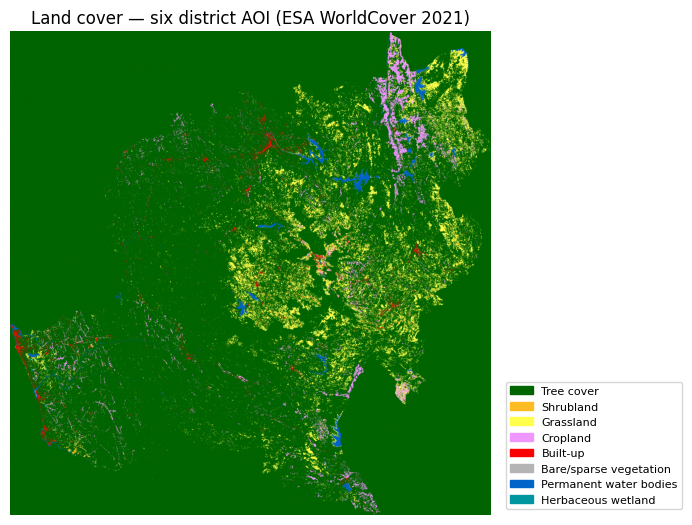

In [22]:
present_classes = sorted(set(arr.flatten()) & set(worldcover_classes.keys()))
colors = [worldcover_classes[c][1] for c in present_classes]
labels = [worldcover_classes[c][0] for c in present_classes]

cmap = ListedColormap(colors)
norm = BoundaryNorm(present_classes + [present_classes[-1] + 10], cmap.N)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(arr, cmap=cmap, norm=norm)
ax.set_title("Land cover — six district AOI (ESA WorldCover 2021)")
ax.axis("off")
patches = [plt.Rectangle((0,0),1,1, color=c) for c in colors]
ax.legend(patches, labels, loc="lower left", bbox_to_anchor=(1.02, 0), fontsize=8)
plt.tight_layout()
plt.show()

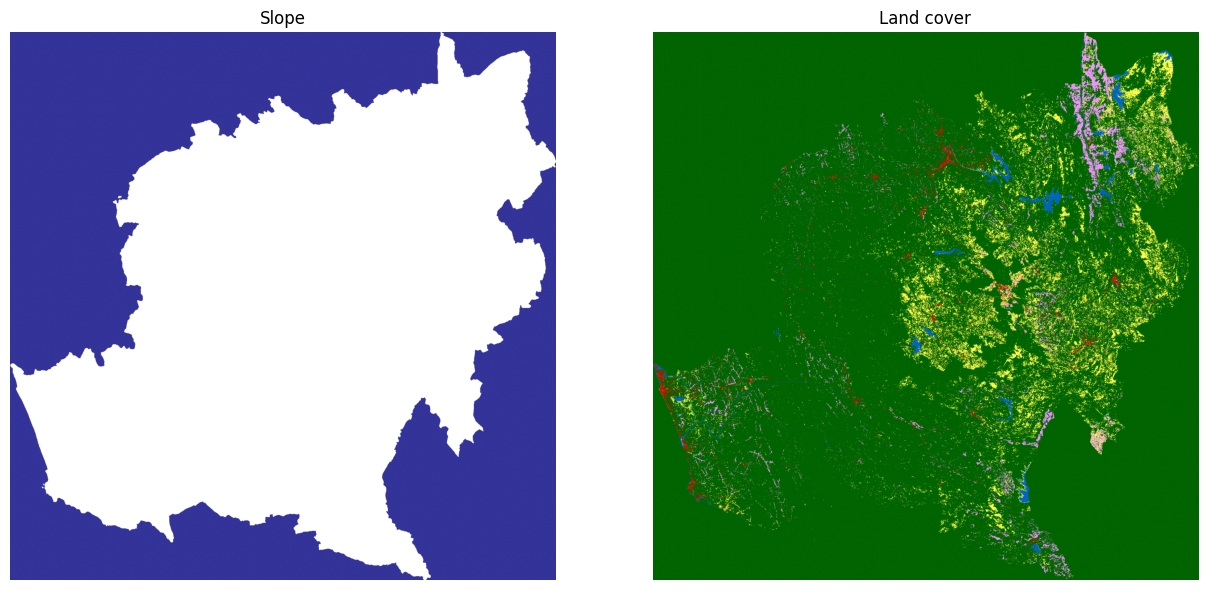

In [23]:
#Slope and land cover
with rasterio.open(DATA_PROCESSED / "slope.tif") as src:
    scale = max(src.width, src.height) / 2000
    slope_small = src.read(1, out_shape=(int(src.height/scale), int(src.width/scale)), resampling=Resampling.bilinear)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(slope_small, cmap="terrain")
axes[0].set_title("Slope")
axes[0].axis("off")
axes[1].imshow(arr, cmap=cmap, norm=norm)
axes[1].set_title("Land cover")
axes[1].axis("off")
plt.tight_layout()
plt.show()

### Rainfall processing

In [28]:
import pandas as pd
# Load and clean
raw = pd.read_csv(DATA_RAW / "lka-rainfall-subnat-full.csv")

if raw.iloc[0].astype(str).str.startswith("#").any():
    rainfall = raw.iloc[1:].reset_index(drop=True)
else:
    rainfall = raw.copy()

numeric_cols = ["rfh", "r1h", "r3h", "rfh_avg", "r1h_avg", "r3h_avg", "rfq", "r1q", "r3q", "n_pixels"]
for col in numeric_cols:
    rainfall[col] = pd.to_numeric(rainfall[col], errors="coerce")
rainfall["date"] = pd.to_datetime(rainfall["date"])

if "type" in rainfall.columns:
    print(rainfall["type"].unique())
else:
    print(rainfall["version"].unique())

pcode_col = [c for c in rainfall.columns if "PCODE" in c.upper()][0]
print("P-code column:", pcode_col)

['final' 'prelim']
P-code column: PCODE


In [30]:
# Filter to your six districts, observed data only
target_pcodes = aoi["adm2_pcode"].tolist()

type_col = "type" if "type" in rainfall.columns else "version"

rainfall_aoi = rainfall[
    rainfall[pcode_col].isin(target_pcodes) &
    (rainfall[type_col] == "final")
].copy()

print(f"{len(rainfall_aoi)} rows across {rainfall_aoi[pcode_col].nunique()} districts")

9828 rows across 6 districts


In [31]:
# Compute and save the static (long-term average) feature
static_rainfall = (
    rainfall_aoi.groupby(pcode_col)["rfh_avg"]
    .mean()
    .reset_index()
    .rename(columns={pcode_col: "adm2_pcode", "rfh_avg": "rainfall_dekad_avg_mm"})
)
static_rainfall.to_parquet(DATA_PROCESSED / "rainfall_static_district.parquet")

# Also save the full time series for the trigger notebook later
rainfall_aoi.to_parquet(DATA_PROCESSED / "rainfall_timeseries_district.parquet")

print(static_rainfall.sort_values("rainfall_dekad_avg_mm", ascending=False))

  adm2_pcode  rainfall_dekad_avg_mm
0       LK13              92.672028
5       LK92              79.620586
4       LK91              76.637810
2       LK23              69.856326
1       LK21              66.415273
3       LK81              57.518724


### District rainfall — choropleth map

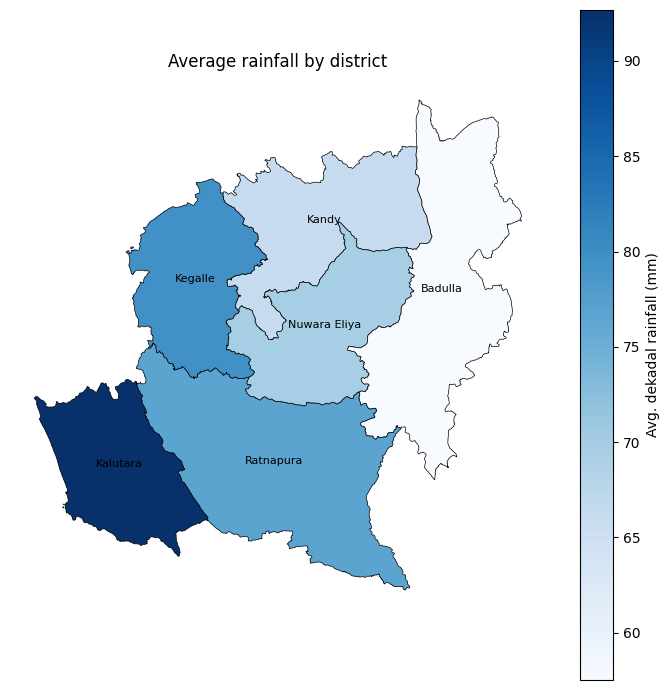

In [32]:
import geopandas as gpd

# aoi (districts layer) already has adm2_pcode; static_rainfall has the same column
aoi_rainfall = aoi.merge(static_rainfall, on="adm2_pcode", how="left")

fig, ax = plt.subplots(figsize=(7, 7))
aoi_rainfall.plot(
    column="rainfall_dekad_avg_mm",
    cmap="Blues",
    edgecolor="black",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "Avg. dekadal rainfall (mm)"},
    ax=ax,
)

# label each district with its name
for idx, row in aoi_rainfall.iterrows():
    centroid = row.geometry.centroid
    ax.annotate(row["adm2_name"], (centroid.x, centroid.y), fontsize=8, ha="center")

ax.set_title("Average rainfall by district")
ax.axis("off")
plt.tight_layout()
plt.show()